### ISA 616 Churn Project--Preprocess/Clean Data
Lucas Brown, Lauren Gualtieri, Piper Willinger

October 12, 2026

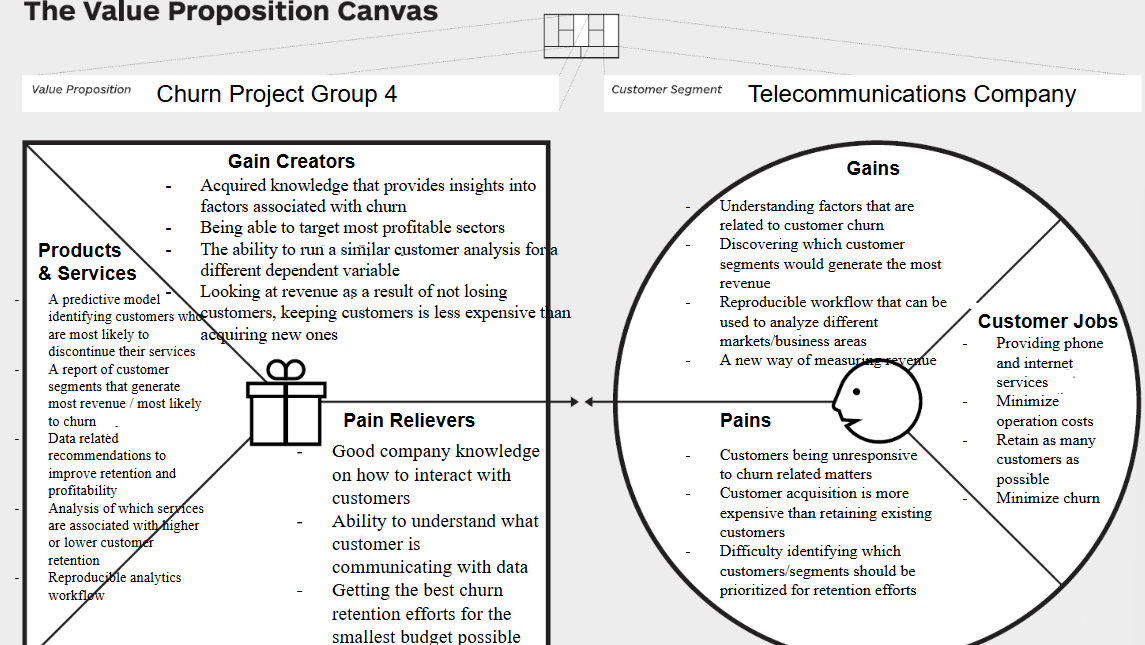

This project examines a dataset containing information on various demographic variables that could potentially help identify factors associated with customer churn for a telecommunications company. The telecommunication company is particularyly interested in eliminating churn as much as possible because the job function of recruting more customers is more costly to the business than maintaining customers. The analysis is intended to help the company better understand the demographics of their customers that churn and identify segments that are most likely to churn and/or not churn. Furthermore, we hope to provide the telecommunications company with not only relevant findings on churn data, but also provide them with a reproducible workflow that allows them to test other independent variables with customer demographic data.

**The primary audience for this preprocessing notebook is our fellow analysts and project team members, who can review, reproduce, and extend the analysis. The telecommunications company's decision-makers are the eventual audience for the business recommendations.**

### Data Description

The dataset contains 7,043 customer observations and 17 variables from the IBM Telco Customer Churn class project dataset. Each row represents an individual customer, uniquely identified by `customerID`.

The response variable, `Churn`, indicates whether a customer discontinued service (Yes/No). The remaining variables describe demographic characteristics, account tenure, services, contracts, payment methods, customer satisfaction, and other customer behaviors.

The dataset includes categorical and numerical predictors. Because the objective is to understand and predict customer churn, `customerID` will be retained for record identification but excluded from predictive modeling.

The initial assessment identified missing values and inconsistencies between certain service-related variables, which are addressed in the preprocessing sections below.

First, we begin by importing the necessary libraries for EDA and cleaning and also look at the first 5 rows or the dataset as well as the .info()

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the original dataset
df = pd.read_csv("Churn_class_project.csv")

# Inspect the dataset
print("Dataset shape:", df.shape)
display(df.head())
df.info()

Dataset shape: (7043, 17)


,customerID,gender,SeniorCitizen,tenure,PhoneService,MultipleLines,InternetService,TechSupport,Contract,PaperlessBilling,PaymentMethod,CustomerAge,AnnualIncome,MonthlyCallMinutes,AveragePaymentDelayDays,CustomerSatisfactionScore,Churn
0,7590-VHVEG,Female,No,1.0,No,Yes,DSL,No,Month-to-month,No,Electronic check,77.0,39408.0,0.0,11.4,6.0,No
1,5575-GNVDE,Male,No,34.0,Yes,No,DSL,No,One year,Yes,Mailed check,22.0,102292.0,375.1,0.5,6.6,No
2,3668-QPYBK,Male,No,2.0,Yes,No phone service,DSL,No,Month-to-month,Yes,Mailed check,43.0,26869.0,373.6,3.4,6.2,Yes
3,7795-CFOCW,Male,No,45.0,No,Yes,DSL,Yes,One year,Yes,NaN,71.0,90565.0,0.0,1.4,6.8,No
4,9237-HQITU,Female,No,2.0,Yes,No,Fiber optic,No,Month-to-month,Yes,Electronic check,NaN,83510.0,221.7,5.8,6.3,Yes


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 17 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   customerID                 7043 non-null   object 
 1   gender                     7043 non-null   object 
 2   SeniorCitizen              7043 non-null   object 
 3   tenure                     6761 non-null   float64
 4   PhoneService               7043 non-null   object 
 5   MultipleLines              7043 non-null   object 
 6   InternetService            7043 non-null   object 
 7   TechSupport                7043 non-null   object 
 8   Contract                   7043 non-null   object 
 9   PaperlessBilling           7043 non-null   object 
 10  PaymentMethod              6761 non-null   object 
 11  CustomerAge                6973 non-null   float64
 12  AnnualIncome               6973 non-null   float64
 13  MonthlyCallMinutes         6973 non-null   float

Next, we identified the variables with missing values

In [ ]:
missing_summary = pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing Percent": (df.isna().mean() * 100).round(2)
})

display(
    missing_summary[missing_summary["Missing Count"] > 0]
    .sort_values("Missing Count", ascending=False)
)

,Missing Count,Missing Percent
tenure,282,4.00
PaymentMethod,282,4.00
CustomerAge,70,0.99
AnnualIncome,70,0.99
MonthlyCallMinutes,70,0.99
AveragePaymentDelayDays,70,0.99
CustomerSatisfactionScore,70,0.99


The missing-value analysis revealed that seven variables contain missing observations. Tenure and PaymentMethod have the highest missing counts, with 282 missing values each (4.00%). Five other variables each contain 70 missing values (0.99%).

These missing observations require further investigation before cleaning because simply removing incomplete records could reduce the sample size or introduce bias. We will examine whether missing values occur together and evaluate appropriate treatments based on each variable's meaning and distribution.

In [ ]:
display(pd.crosstab(
    df["tenure"].isna(),
    df["PaymentMethod"].isna()
))

incomplete = df.isna().any(axis=1)

print("Incomplete records:", incomplete.sum())
print("Percent incomplete:", round(incomplete.mean() * 100, 2))

display(
    df.groupby("Churn")["tenure"]
      .apply(lambda x: round(x.isna().mean() * 100, 2))
)

PaymentMethod,False,True
tenure,,
False,6486,275
True,275,7


Incomplete records: 877
Percent incomplete: 12.45


,tenure
Churn,
No,3.69
Yes,4.87


Further investigation revealed that although tenure and PaymentMethod each contain 282 missing values, only seven customers are missing both variables. This suggests that missing values in these two fields generally occur in different customer records.

Additionally, 877 customers (12.45% of the dataset) have at least one missing value. Removing all incomplete observations would substantially reduce the available data. Therefore, we will evaluate variable-specific cleaning methods rather than automatically removing all incomplete records.

We then checked for any duplicate rows and checked for telephone-service consitency. We also did .describe() to get the summary statistics for the numeric variables.

In [ ]:
# Duplicate IDs and duplicate rows
print("Duplicate IDs:", df["customerID"].duplicated().sum())
print("Duplicate rows:", df.duplicated().sum())

# Check telephone-service consistency
display(pd.crosstab(
    df["PhoneService"],
    df["MultipleLines"]
))

# Inspect numeric summaries
display(df.describe())

Duplicate IDs: 0
Duplicate rows: 0


MultipleLines,No,No phone service,Yes
PhoneService,,,
No,318,70,294
Yes,3072,612,2677


,tenure,CustomerAge,AnnualIncome,MonthlyCallMinutes,AveragePaymentDelayDays,CustomerSatisfactionScore
count,6761.000000,6973.000000,6973.000000,6973.000000,6973.000000,6973.000000
mean,32.441651,46.689230,62124.351642,467.187079,3.325742,6.859587
std,24.561694,16.576262,29417.754988,226.335372,3.003101,1.387753
min,0.000000,18.000000,18000.000000,0.000000,0.000000,1.500000
25%,9.000000,35.000000,41357.000000,346.100000,1.200000,5.900000
50%,29.000000,44.000000,55841.000000,494.500000,2.500000,6.900000
75%,56.000000,57.000000,76273.000000,623.100000,4.500000,7.800000
max,72.000000,90.000000,250000.000000,1161.500000,24.000000,10.000000


The duplicate assessment identified zero duplicate customer IDs and zero completely duplicated records. As a result, no customer records need to be removed for duplication.

However, the telephone-service consistency check identified 1,224 records with conflicting classifications. Specifically, 612 customers without phone service have a MultipleLines value of either "Yes" or "No," while 612 customers with phone service have a MultipleLines value of "No phone service."

These inconsistencies suggest potential data entry or classification errors. Because we cannot definitively determine which variable contains the correct information, we will flag these records for further investigation rather than automatically changing their values.

Next, we made a copy of df to become our clean_df.

In [ ]:
invalid_values = {
    "Negative tenure": (df["tenure"] < 0).sum(),
    "Invalid age": (
        (df["CustomerAge"] < 0) |
        (df["CustomerAge"] > 120)
    ).sum(),
    "Negative income": (df["AnnualIncome"] < 0).sum(),
    "Negative call minutes": (
        df["MonthlyCallMinutes"] < 0
    ).sum(),
    "Negative payment delays": (
        df["AveragePaymentDelayDays"] < 0
    ).sum(),
    "Invalid satisfaction scores": (
        (df["CustomerSatisfactionScore"] < 1) |
        (df["CustomerSatisfactionScore"] > 10)
    ).sum()
}

display(pd.Series(invalid_values, name="Invalid Count"))

categorical_cols = df.select_dtypes(include="object").columns

for col in categorical_cols:
    if col != "customerID":
        print(f"\n{col}:")
        print(df[col].value_counts(dropna=False))

,Invalid Count
Negative tenure,0
Invalid age,0
Negative income,0
Negative call minutes,0
Negative payment delays,0
Invalid satisfaction scores,0



gender:
gender
Male      3555
Female    3488
Name: count, dtype: int64

SeniorCitizen:
SeniorCitizen
No     5901
Yes    1142
Name: count, dtype: int64

PhoneService:
PhoneService
Yes    6361
No      682
Name: count, dtype: int64

MultipleLines:
MultipleLines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64

InternetService:
InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

TechSupport:
TechSupport
No                     3473
Yes                    2044
No internet service    1526
Name: count, dtype: int64

Contract:
Contract
Month-to-month    3875
Two year          1695
One year          1473
Name: count, dtype: int64

PaperlessBilling:
PaperlessBilling
Yes    4171
No     2872
Name: count, dtype: int64

PaymentMethod:
PaymentMethod
Electronic check             2260
Mailed check                 1548
Bank transfer (automatic)    1484
Credit card (automatic)      1469
NaN             

We assessed the numeric variables for values that violated basic business rules, including negative tenure, income, call minutes, and payment delays, as well as customer satisfaction scores outside the documented 1–10 range. No values were found that violated these checks.

We also examined the unique values of each categorical variable to identify potentially inconsistent labels. This assessment helps determine whether categorical standardization or additional corrections are necessary before further analysis.

In [ ]:
df_clean = df.copy()

# Identify possible service inconsistencies
phone_conflict = (
    ((df_clean["PhoneService"] == "No") &
     (df_clean["MultipleLines"] != "No phone service"))
    |
    ((df_clean["PhoneService"] == "Yes") &
     (df_clean["MultipleLines"] == "No phone service"))
)

df_clean["PhoneLineConflict"] = phone_conflict

print("Flagged records:", phone_conflict.sum())

Flagged records: 1224


### Missing-Value Treatment

After examining the missing values, we decided to preserve all customer records rather than remove incomplete observations. We used median imputation for missing numeric values and assigned missing PaymentMethod values to a separate "Missing" category.

We also created indicators to identify which numeric values were originally missing. This preserves information about data quality for future analysis.

The conflicting phone-service records were retained and flagged because we could not confidently determine which classification was correct.

In [ ]:
numeric_missing = [
    "tenure",
    "CustomerAge",
    "AnnualIncome",
    "MonthlyCallMinutes",
    "AveragePaymentDelayDays",
    "CustomerSatisfactionScore"
]

for col in numeric_missing:
    df_clean[col + "_WasMissing"] = df_clean[col].isna()

for col in numeric_missing:
    median_value = df_clean[col].median()
    df_clean[col] = df_clean[col].fillna(median_value)

df_clean["PaymentMethod"] = (
    df_clean["PaymentMethod"].fillna("Missing")
)

display(df_clean.isna().sum())

,0
customerID,0
gender,0
SeniorCitizen,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
TechSupport,0
Contract,0
PaperlessBilling,0


After reviewing the missing-value patterns, we elected to retain incomplete customer records rather than discard them. Numeric missing values were replaced using the median of each respective variable, while missing PaymentMethod values were classified under a separate "Missing" category.

Median imputation was selected as a straightforward method that is less influenced by extreme values than mean imputation. We also created missingness indicators for affected numeric variables to preserve information about which observations were originally incomplete.

The inconsistent phone-service records were retained and flagged because the available data does not establish which conflicting value is correct. These records require additional consideration before using the affected variables in predictive modeling.

These preprocessing decisions preserve the original customer sample, although imputed values should be interpreted as estimates rather than observed customer information.

In [ ]:
comparison = pd.DataFrame({
    "Metric": [
        "Number of customers",
        "Missing values",
        "Duplicate customer IDs",
        "Phone-service conflicts"
    ],
    "Before": [
        len(df),
        df.isna().sum().sum(),
        df["customerID"].duplicated().sum(),
        phone_conflict.sum()
    ],
    "After": [
        len(df_clean),
        df_clean.isna().sum().sum(),
        df_clean["customerID"].duplicated().sum(),
        df_clean["PhoneLineConflict"].sum()
    ]
})

display(comparison)

,Metric,Before,After
0,Number of customers,7043,7043
1,Missing values,914,0
2,Duplicate customer IDs,0,0
3,Phone-service conflicts,1224,1224


### Preprocessing Results and Validation

The preprocessing process retained all 7,043 customer records while addressing 914 missing values across seven variables. Following the cleaning process, the dataset contains no remaining missing values.

No duplicate customer IDs were identified in either the original or cleaned dataset.

The 1,224 phone-service inconsistencies remain flagged rather than corrected because the available data does not establish which classification is accurate.

Overall, the cleaning process improved data completeness while preserving customer records. However, future analyses should consider the limitations of imputed values and unresolved service inconsistencies.

### Computing Environment

This analysis was conducted using Python in Google Colab, a cloud-based notebook environment. We used pandas and NumPy for data manipulation and preprocessing, along with Matplotlib and Seaborn for data visualization.

The following output documents the Python version, operating system, and package versions used for this analysis to support reproducibility.

In [ ]:
import sys
import platform
import matplotlib

print("Python:", sys.version.split()[0])
print("Operating System:", platform.platform())
print("pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Seaborn:", sns.__version__)

Python: 3.13.16
Operating System: Linux-6.6.122+-x86_64-with-glibc2.39
pandas: 2.2.3
NumPy: 2.1.3
Matplotlib: 3.10.0
Seaborn: 0.13.2


In [ ]:
df_clean.to_csv(
    "Churn_class_project_cleaned.csv",
    index=False
)

print("Cleaned dataset saved successfully.")
print("Final dimensions:", df_clean.shape)

Cleaned dataset saved successfully.
Final dimensions: (7043, 24)
